# Task 1 · EDA on Retail Sales Data
**Track:** Data Analytics · **Level:** 1

**Objective:** Perform a thorough Exploratory Data Analysis on a retail sales dataset to uncover patterns, customer behaviour trends and actionable business insights.

**Tech stack:** Python, pandas, matplotlib, seaborn, Jupyter Notebook

| # | Checklist item | Section |
|---|---|---|
| 1 | Load dataset and run initial inspection (shape, dtypes, nulls) | 1 |
| 2 | Descriptive statistics (mean, median, mode, std) | 2 |
| 3 | Time series: monthly and quarterly sales trends | 3 |
| 4 | Customer demographics: age groups, gender | 4 |
| 5 | Product analysis: top 10 products, revenue by category | 5 |
| 6 | Correlation heatmap | 6 |
| 7 | Additional visualisation with a non-obvious insight | 7 |
| 8 | Markdown observations after each chart | throughout |
| 9 | Conclusion with at least 3 actionable recommendations | 8 |

### How to use your own dataset
Download a retail dataset from Kaggle (search **"retail sales dataset"**, "superstore sales" or "e-commerce sales dataset"), save the CSV next to this notebook and set `DATA_PATH` in the first code cell of Section 1. If the file is not found, the notebook builds a clearly labelled **sample dataset** so every cell still runs end to end.

> The written observations in this notebook describe the bundled sample data. If you load a real Kaggle file, re-read each observation against your own charts and edit the numbers.

## 0. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

# Colour-blind-safe categorical order, plus a one-hue sequential ramp and a blue<->red diverging ramp
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
CATEGORICAL = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#2a78d6", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div_red_blue", ["#e34948", "#f0efec", "#2a78d6"])

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

money = mtick.StrMethodFormatter("{x:,.0f}")

## 1. Load the dataset and run an initial inspection

The analysis expects these columns (rename yours with `RENAME` if they differ):
`Date`, `Customer ID`, `Gender`, `Age`, `Product Category`, `Quantity`, `Unit Price`, `Total Amount`, and optionally `Product Name`.

In [2]:
DATA_PATH = "retail_sales_dataset.csv"   # <- your Kaggle CSV goes here

# Map YOUR column names to the standard names used in this notebook, e.g.
# RENAME = {"Price per Unit": "Unit Price", "Order Date": "Date"}
RENAME = {}


def make_sample_data(n=6000, seed=42):
    """Synthetic retail transactions, used only when DATA_PATH does not exist."""
    rng = np.random.default_rng(seed)
    catalog = {
        "Electronics": {"Wireless Earbuds": 60, "Smart Watch": 180, "Bluetooth Speaker": 75, "Tablet": 320, "Power Bank": 30},
        "Clothing": {"Denim Jacket": 70, "Running Shoes": 85, "Cotton T-Shirt": 20, "Winter Coat": 140, "Yoga Pants": 40},
        "Beauty": {"Face Serum": 45, "Perfume": 90, "Lipstick": 18, "Shampoo": 15, "Moisturiser": 28},
        "Home & Kitchen": {"Air Fryer": 110, "Coffee Maker": 65, "Cookware Set": 130, "Bed Sheet Set": 55, "LED Lamp": 25},
        "Books & Stationery": {"Novel": 12, "Notebook Set": 10, "Fountain Pen": 35, "Planner": 18, "Cookbook": 22},
    }
    cats = list(catalog)
    base_w = {"Electronics": 0.18, "Clothing": 0.28, "Beauty": 0.24, "Home & Kitchen": 0.18, "Books & Stationery": 0.12}
    prod_w = {c: rng.dirichlet(np.ones(len(catalog[c])) * 3) for c in cats}

    # Customers: heavy-tailed activity, so a minority of customers drive most of the sales
    n_cust = 1500
    cust_ids = np.array([f"CUST{i:04d}" for i in range(1, n_cust + 1)])
    cust_age = np.clip(rng.normal(38, 12, n_cust), 18, 70).round().astype(int)
    cust_gender = rng.choice(["Female", "Male"], n_cust, p=[0.52, 0.48])
    activity = rng.pareto(1.6, n_cust) + 1
    activity /= activity.sum()

    # Dates: Nov-Dec peak, January dip, weekend uplift, mild year-on-year growth
    days = pd.date_range("2023-01-01", "2024-12-31")
    month_w = {1: .75, 2: .8, 3: .9, 4: .95, 5: 1.0, 6: 1.0, 7: .95, 8: .95, 9: 1.0, 10: 1.1, 11: 1.5, 12: 1.8}
    w = np.array([month_w[d.month] * (1.2 if d.dayofweek >= 5 else 1.0) * (1 + 0.15 * (d.year - 2023)) for d in days])
    dates = rng.choice(days.to_numpy(), n, p=w / w.sum())

    rows = []
    for i, (d, ci) in enumerate(zip(dates, rng.choice(n_cust, n, p=activity)), start=1):
        g, age = cust_gender[ci], cust_age[ci]
        cw = dict(base_w)
        if g == "Female":
            cw["Beauty"] *= 1.5; cw["Electronics"] *= 0.7
        else:
            cw["Electronics"] *= 1.4; cw["Beauty"] *= 0.6
        if age < 30:
            cw["Clothing"] *= 1.2
        p = np.array([cw[c] for c in cats]); p /= p.sum()
        cat = rng.choice(cats, p=p)
        prod = rng.choice(list(catalog[cat]), p=prod_w[cat])
        qty = rng.choice([1, 2, 3, 4], p=[.80, .15, .04, .01] if cat == "Electronics" else [.45, .28, .17, .10])
        price = round(catalog[cat][prod] * rng.uniform(0.9, 1.1), 2)
        rows.append((f"T{i:05d}", pd.Timestamp(d), cust_ids[ci], g, int(age), cat, prod, int(qty), price, round(qty * price, 2)))
    return pd.DataFrame(rows, columns=["Transaction ID", "Date", "Customer ID", "Gender", "Age",
                                       "Product Category", "Product Name", "Quantity", "Unit Price", "Total Amount"])


if Path(DATA_PATH).exists():
    try:
        df = pd.read_csv(DATA_PATH)
    except UnicodeDecodeError:
        df = pd.read_csv(DATA_PATH, encoding="latin-1")
    print(f"Loaded {DATA_PATH}")
else:
    df = make_sample_data()
    df.to_csv("sample_retail_sales.csv", index=False)
    print(f"'{DATA_PATH}' not found -> using a generated SAMPLE dataset (saved as sample_retail_sales.csv).")

# Standardise column names and types
df = df.rename(columns=RENAME)
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
if "Total Amount" not in df.columns:
    df["Total Amount"] = df["Quantity"] * df["Unit Price"]
if "Product Name" not in df.columns:
    df["Product Name"] = df["Product Category"]
    print("No 'Product Name' column found -> using Product Category as the product level.")
df = df.dropna(subset=["Date"]).sort_values("Date").reset_index(drop=True)

'retail_sales_dataset.csv' not found -> using a generated SAMPLE dataset (saved as sample_retail_sales.csv).


In [3]:
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Date range: {df['Date'].min():%d %b %Y} -> {df['Date'].max():%d %b %Y}\n")
display(df.head())

print("Column data types")
display(df.dtypes.rename("dtype").to_frame())

nulls = df.isna().sum().rename("null_count").to_frame()
nulls["null_%"] = nulls["null_count"] / len(df) * 100
print("Null value check")
display(nulls)
print("Duplicate rows:", df.duplicated().sum())

Shape: 6,000 rows x 10 columns
Date range: 01 Jan 2023 -> 31 Dec 2024



,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Product Name,Quantity,Unit Price,Total Amount
0,T05219,2023-01-01,CUST0692,Male,18,Clothing,Winter Coat,1,147.91,147.91
1,T02383,2023-01-01,CUST0003,Male,32,Home & Kitchen,Coffee Maker,2,67.31,134.62
2,T00834,2023-01-01,CUST0911,Male,26,Electronics,Bluetooth Speaker,1,75.26,75.26
3,T05547,2023-01-01,CUST0696,Male,44,Beauty,Lipstick,4,17.37,69.48
4,T05570,2023-01-01,CUST0632,Female,32,Home & Kitchen,Bed Sheet Set,3,51.88,155.64


Column data types


,dtype
Transaction ID,str
Date,datetime64[us]
Customer ID,str
Gender,str
Age,int64
Product Category,str
Product Name,str
Quantity,int64
Unit Price,float64
Total Amount,float64


Null value check


,null_count,null_%
Transaction ID,0,0.00
Date,0,0.00
Customer ID,0,0.00
Gender,0,0.00
Age,0,0.00
Product Category,0,0.00
Product Name,0,0.00
Quantity,0,0.00
Unit Price,0,0.00
Total Amount,0,0.00


Duplicate rows: 0


**Observations**
- The sample holds 6,000 transactions in 10 columns, covering Jan 2023 to Dec 2024.
- There are no null values and no duplicate rows, so no imputation or de-duplication is needed. With a real Kaggle file, handle any nulls here before going further.
- `Date` is parsed to datetime; `Age` and `Quantity` are integers and the money columns are floats, so the dtypes are ready for analysis.
- 6,000 transactions come from only 1,369 distinct customers, so many customers buy more than once. That is why the demographic charts later count one row per customer.

## 2. Descriptive statistics

In [4]:
num_cols = ["Age", "Quantity", "Unit Price", "Total Amount"]

stats = pd.DataFrame({
    "mean": df[num_cols].mean(),
    "median": df[num_cols].median(),
    "mode": df[num_cols].mode().iloc[0],
    "std": df[num_cols].std(),
})
display(stats)

print("Full summary")
display(df[num_cols].describe().T)

,mean,median,mode,std
Age,37.33,37.00,34.00,11.28
Quantity,1.81,1.00,1.00,0.98
Unit Price,68.33,49.27,16.28,61.47
Total Amount,116.88,75.01,16.21,113.73


Full summary


,count,mean,std,min,25%,50%,75%,max
Age,"6,000.00",37.33,11.28,18.00,29.00,37.00,45.00,70.00
Quantity,"6,000.00",1.81,0.98,1.00,1.00,1.00,2.00,4.00
Unit Price,"6,000.00",68.33,61.47,9.02,22.86,49.27,88.75,349.70
Total Amount,"6,000.00",116.88,113.73,9.04,38.88,75.01,156.68,"1,035.84"


**Observations**
- Order value is right-skewed: the mean (116.88) is well above the median (75.01) and the standard deviation (113.73) is almost as large as the mean. A minority of big-ticket orders (maximum 1,035.84) pull the average up, so the median is the better "typical order" figure.
- Unit price shows the same skew (mean 68.33 vs median 49.27).
- Most orders are a single unit: the median quantity is 1 even though the mean is 1.81.
- Age is roughly symmetric (mean 37.3, median 37, std 11.3), so there are no extreme age outliers.
- The mode of a continuous column such as `Unit Price` (16.28) just reflects the most repeated price point and is not meaningful on its own.

## 3. Time series analysis: monthly and quarterly sales

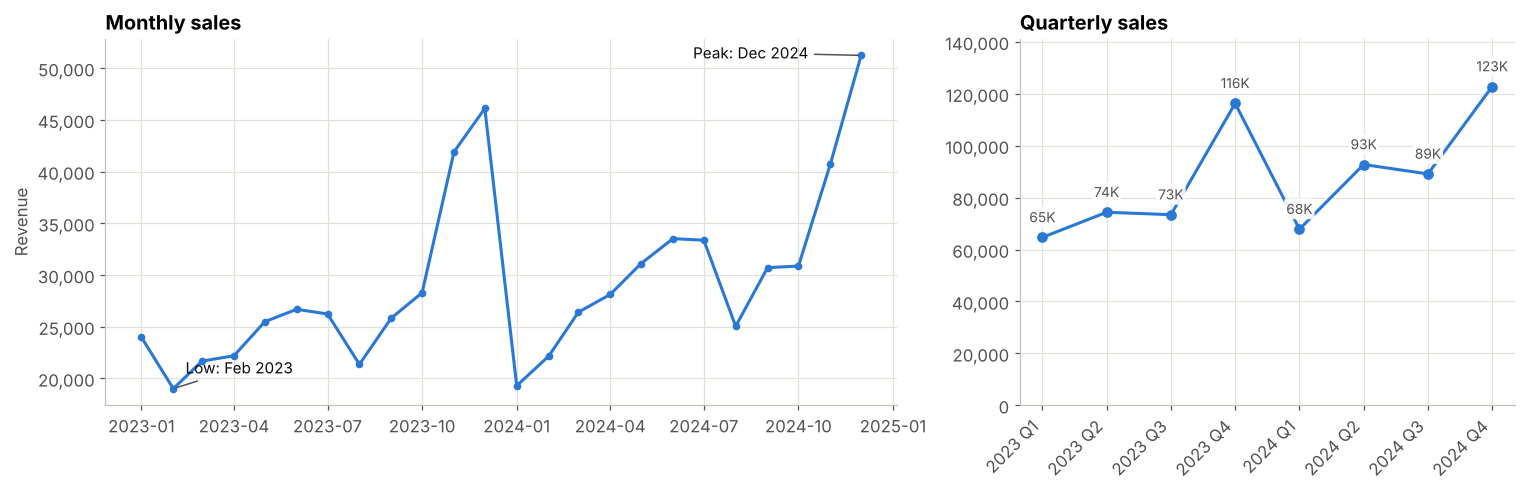

Peak month: Dec 2024 (51,234) | Lowest month: Feb 2023 (19,013)
Best quarter: 2024 Q4 (122,790)
Nov+Dec share of all revenue: 25.7%
Revenue by year: {2023: '328,762', 2024: '372,508'}


In [5]:
monthly = df.set_index("Date")["Total Amount"].resample("MS").sum()
quarterly = df.set_index("Date")["Total Amount"].resample("QS").sum()
q_labels = [f"{p.year} Q{p.quarter}" for p in quarterly.index.to_period("Q")]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})

ax = axes[0]
ax.plot(monthly.index, monthly.values, color=BLUE, lw=2, marker="o", ms=4)
ax.yaxis.set_major_formatter(money)
ax.set_title("Monthly sales")
ax.set_ylabel("Revenue")
peak, low = monthly.idxmax(), monthly.idxmin()
ax.annotate(f"Peak: {peak:%b %Y}", (peak, monthly.max()), xytext=(-110, -2), textcoords="offset points",
            color=INK, fontsize=10, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.annotate(f"Low: {low:%b %Y}", (low, monthly.min()), xytext=(8, 10), textcoords="offset points",
            color=INK, fontsize=10, arrowprops=dict(arrowstyle="-", color=MUTED))

ax = axes[1]
ax.plot(range(len(quarterly)), quarterly.values, color=BLUE, lw=2, marker="o", ms=6)
ax.set_xticks(range(len(quarterly)))
ax.set_xticklabels(q_labels, rotation=45, ha="right")
ax.yaxis.set_major_formatter(money)
ax.set_title("Quarterly sales")
for i, v in enumerate(quarterly.values):
    ax.annotate(f"{v/1e3:,.0f}K", (i, v), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=9, color=MUTED,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9))
ax.set_ylim(0, quarterly.max() * 1.15)

plt.tight_layout()
plt.show()

# Numbers behind the chart
by_month = df.groupby(df["Date"].dt.month)["Total Amount"].sum()
yearly = df.groupby(df["Date"].dt.year)["Total Amount"].sum()
print(f"Peak month: {peak:%b %Y} ({monthly.max():,.0f}) | Lowest month: {low:%b %Y} ({monthly.min():,.0f})")
print(f"Best quarter: {q_labels[int(np.argmax(quarterly.values))]} ({quarterly.max():,.0f})")
print(f"Nov+Dec share of all revenue: {by_month.loc[[11, 12]].sum() / by_month.sum():.1%}")
print("Revenue by year:", {int(k): f"{v:,.0f}" for k, v in yearly.items()})

**Observations**
- Sales are strongly seasonal: November and December together bring in 25.7% of all revenue, and the peak month is Dec 2024 (51,234).
- Q4 is the best quarter in both years (2023 Q4 about 116K, 2024 Q4 about 123K, up roughly 5.6% year on year).
- There is a sharp post-holiday crash: January 2024 is 58% below December 2023, and the lowest month overall is Feb 2023 (19,013). 2024 Q1 is about 42% below 2023 Q4.
- Underlying growth is positive: 2024 revenue (372,508) is about 13% above 2023 (328,762), and 2024 Q2 and Q3 sit above their 2023 equivalents.
- There is a smaller mid-year bump in May to July and a dip in August in both years.

## 4. Customer demographics: age groups and gender

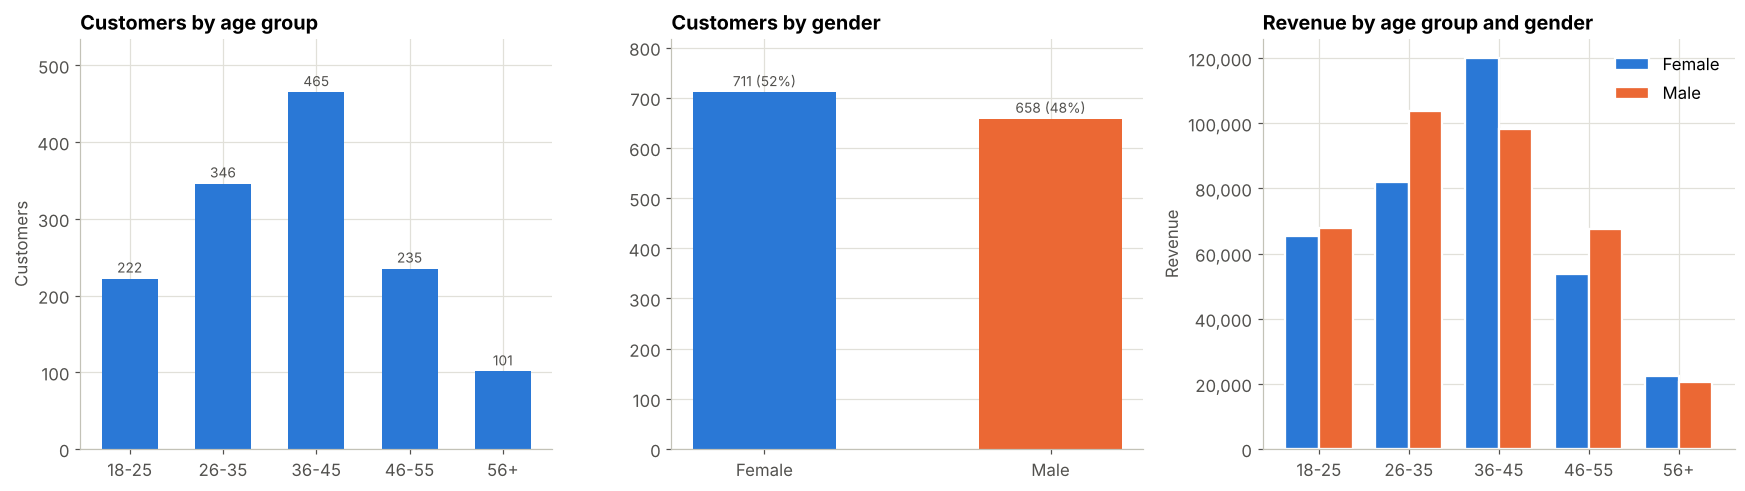

Median customer age: 38
Revenue share by gender: {'Female': '49.0%', 'Male': '51.0%'}
Revenue share by age group: {'18-25': '19.0%', '26-35': '26.5%', '36-45': '31.1%', '46-55': '17.3%', '56+': '6.1%'}
Revenue per customer by age group: {'18-25': '600', '26-35': '537', '36-45': '469', '46-55': '516', '56+': '425'}


In [6]:
bins = [0, 25, 35, 45, 55, 200]
labels = ["18-25", "26-35", "36-45", "46-55", "56+"]
df["Age Group"] = pd.cut(df["Age"], bins=bins, labels=labels)

# One row per customer, so repeat buyers are not counted several times
customers = df.drop_duplicates("Customer ID")[["Customer ID", "Age", "Gender", "Age Group"]]

age_counts = customers["Age Group"].value_counts().reindex(labels)
gender_counts = customers["Gender"].value_counts()
rev_age_gender = df.pivot_table(index="Age Group", columns="Gender", values="Total Amount", aggfunc="sum").reindex(labels)
g_colors = dict(zip(sorted(df["Gender"].unique()), CATEGORICAL))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

ax = axes[0]
bars = ax.bar(age_counts.index, age_counts.values, color=BLUE, width=0.6)
ax.set_title("Customers by age group")
ax.set_ylabel("Customers")
for b, v in zip(bars, age_counts.values):
    ax.annotate(f"{v:,}", (b.get_x() + b.get_width() / 2, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, color=MUTED)
ax.set_ylim(0, age_counts.max() * 1.15)

ax = axes[1]
bars = ax.bar(gender_counts.index, gender_counts.values, color=[g_colors[g] for g in gender_counts.index], width=0.5)
ax.set_title("Customers by gender")
for b, v in zip(bars, gender_counts.values):
    ax.annotate(f"{v:,} ({v / gender_counts.sum():.0%})", (b.get_x() + b.get_width() / 2, v), xytext=(0, 4),
                textcoords="offset points", ha="center", fontsize=9, color=MUTED)
ax.set_ylim(0, gender_counts.max() * 1.15)

ax = axes[2]
rev_age_gender.plot(kind="bar", ax=ax, color=[g_colors[g] for g in rev_age_gender.columns], width=0.75, edgecolor="white", linewidth=1.5)
ax.set_title("Revenue by age group and gender")
ax.set_xlabel("")
ax.set_ylabel("Revenue")
ax.yaxis.set_major_formatter(money)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="", frameon=False)

plt.tight_layout()
plt.show()

print(f"Median customer age: {customers['Age'].median():.0f}")
as_dict = lambda s: {str(k): v for k, v in s.items()}
print("Revenue share by gender:", as_dict((df.groupby('Gender')['Total Amount'].sum() / df['Total Amount'].sum()).map("{:.1%}".format)))
print("Revenue share by age group:", as_dict((df.groupby('Age Group')['Total Amount'].sum() / df['Total Amount'].sum()).map("{:.1%}".format)))
print("Revenue per customer by age group:", as_dict((df.groupby('Age Group')['Total Amount'].sum() / customers.groupby('Age Group').size()).map("{:,.0f}".format)))

**Observations**
- The customer base is concentrated in the 26 to 45 range: 36-45 is the largest group (465 customers, 34%), followed by 26-35 (346). Customers aged 56+ are a small group (101 customers, about 7%) and generate only 6.1% of revenue.
- Gender is nearly balanced (52% female, 48% male customers), and revenue is split almost evenly too (49.0% female, 51.0% male). Men therefore spend slightly more per customer.
- The pattern differs by age: women out-spend men at 36-45 (about 120K vs 98K), while men lead at 26-35 and 46-55.
- Younger customers are the most valuable per head: revenue per customer is about 600 for 18-25, against 469 for 36-45 and 425 for 56+. The 36-45 group matters because of its size, not because of how much each person spends.

## 5. Product analysis: top 10 products and revenue by category

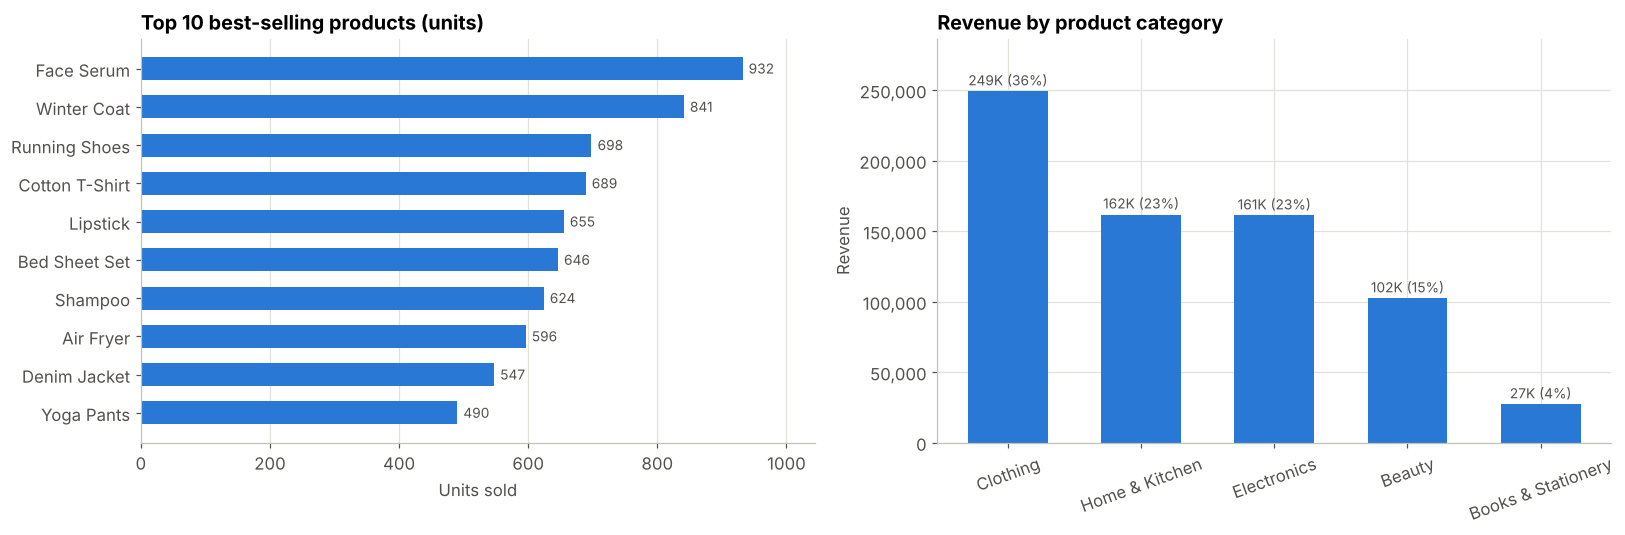

,units_sold,revenue,revenue_share
Product Name,,,
Face Serum,932,"41,995.72",5.99
Winter Coat,841,"117,813.26",16.80
Running Shoes,698,"59,602.95",8.50
Cotton T-Shirt,689,"13,777.15",1.96
Lipstick,655,"11,760.05",1.68
Bed Sheet Set,646,"35,790.52",5.10
Shampoo,624,"9,386.55",1.34
Air Fryer,596,"65,348.41",9.32
Denim Jacket,547,"38,257.70",5.46


Category summary


,revenue,units,avg_price_per_unit
Product Category,,,
Beauty,"102,270.58",2879,35.52
Books & Stationery,"27,118.15",1330,20.39
Clothing,"249,079.53",3265,76.29
Electronics,"161,069.17",1369,117.65
Home & Kitchen,"161,732.96",2042,79.20


In [7]:
top_products = (df.groupby("Product Name")
                  .agg(units_sold=("Quantity", "sum"), revenue=("Total Amount", "sum"))
                  .sort_values("units_sold", ascending=False)
                  .head(10))
cat_revenue = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)
cat_units = df.groupby("Product Category")["Quantity"].sum()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
tp = top_products.iloc[::-1]
bars = ax.barh(tp.index, tp["units_sold"], color=BLUE, height=0.6)
ax.set_title("Top 10 best-selling products (units)")
ax.set_xlabel("Units sold")
ax.grid(axis="y", visible=False)
for b, v in zip(bars, tp["units_sold"]):
    ax.annotate(f"{v:,}", (v, b.get_y() + b.get_height() / 2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=MUTED)
ax.set_xlim(0, tp["units_sold"].max() * 1.12)

ax = axes[1]
bars = ax.bar(cat_revenue.index, cat_revenue.values, color=BLUE, width=0.6)
ax.set_title("Revenue by product category")
ax.set_ylabel("Revenue")
ax.yaxis.set_major_formatter(money)
ax.tick_params(axis="x", rotation=20)
for b, v in zip(bars, cat_revenue.values):
    ax.annotate(f"{v / 1e3:,.0f}K ({v / cat_revenue.sum():.0%})", (b.get_x() + b.get_width() / 2, v), xytext=(0, 4),
                textcoords="offset points", ha="center", fontsize=9, color=MUTED)
ax.set_ylim(0, cat_revenue.max() * 1.15)

plt.tight_layout()
plt.show()

display(top_products.assign(revenue_share=lambda t: t["revenue"] / df["Total Amount"].sum() * 100))

summary = pd.DataFrame({"revenue": cat_revenue, "units": cat_units,
                        "avg_price_per_unit": cat_revenue / cat_units.reindex(cat_revenue.index)})
print("Category summary")
display(summary)

**Observations**
- Units and revenue tell different stories. Face Serum is the best seller by units (932) but earns only about 6% of revenue, while Winter Coat is second by units (841) and is the single biggest revenue product (117.8K, 16.8%).
- Several high-volume items are low-value: Cotton T-Shirt, Lipstick and Shampoo each sell 620 to 690 units but contribute under 2% of revenue each.
- Clothing is the top category with 36% of revenue (249K). Home & Kitchen (23%) and Electronics (23%) are tied, even though Electronics sells only 1,369 units at about 118 per unit.
- Beauty is the second-largest category by units (2,879) but only 15% of revenue, and Books & Stationery is the smallest at 4%.

## 6. Correlation heatmap

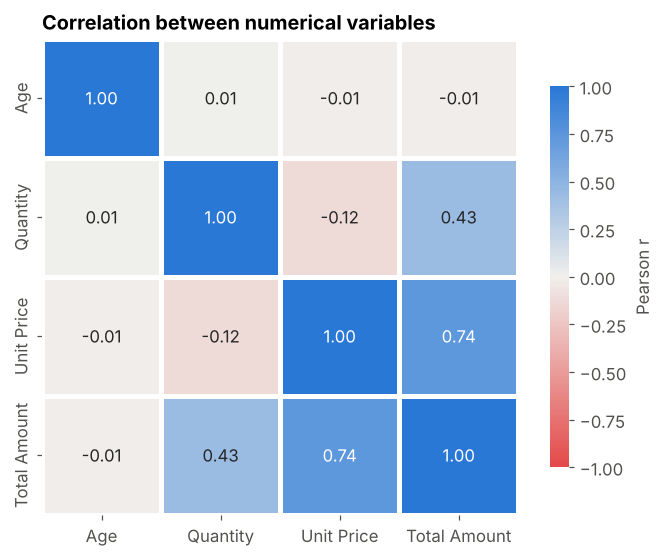

In [8]:
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIV, vmin=-1, vmax=1, center=0,
            square=True, linewidths=2, linecolor="white", cbar_kws={"shrink": 0.8, "label": "Pearson r"}, ax=ax)
ax.set_title("Correlation between numerical variables")
ax.grid(False)
plt.tight_layout()
plt.show()

**Observations**
- `Total Amount` is most strongly related to `Unit Price` (r = 0.74) and moderately to `Quantity` (r = 0.43). Part of this is by construction, because Total Amount = Quantity x Unit Price, so read these two as "what drives order size" rather than as discoveries.
- `Quantity` and `Unit Price` are slightly negatively correlated (r = -0.12): customers buy more units of cheaper items.
- `Age` is essentially uncorrelated with everything (|r| of 0.01 or less), so age alone does not predict how much someone spends per order. Its influence shows up through which categories different groups choose (see Section 7).

## 7. Additional visualisations: how concentrated is revenue, and who spends what where?

Two views that the standard charts above do not show: a Pareto curve of customer revenue (how dependent the business is on a few customers) and the average order value for every age group x category combination.

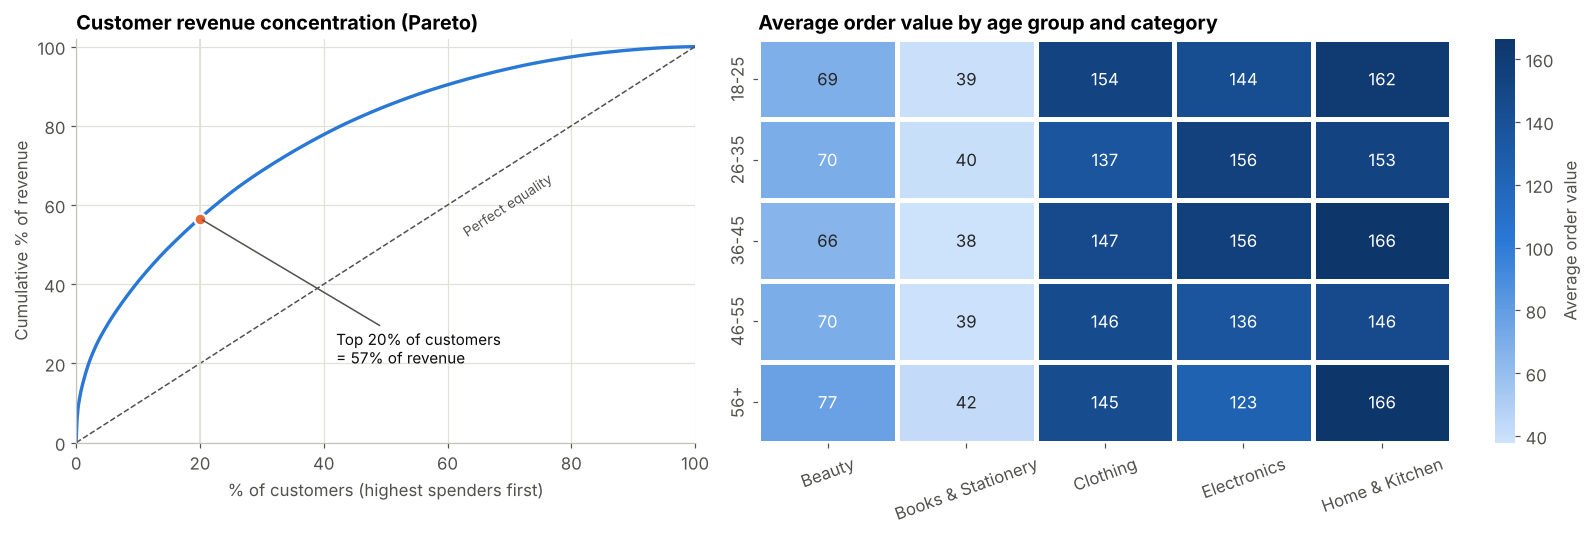

Top 10% of customers = 40.5% of revenue | top 20% = 56.6%
Customers: 1,369 | average orders per customer: 4.4
Bottom 50% of customers = 15.1% of revenue


In [9]:
cust_rev = df.groupby("Customer ID")["Total Amount"].sum().sort_values(ascending=False)
cum_share = cust_rev.cumsum() / cust_rev.sum()
x = np.arange(1, len(cust_rev) + 1) / len(cust_rev)
top20_share = cum_share[x <= 0.20].iloc[-1]
top10_share = cum_share[x <= 0.10].iloc[-1]

aov = df.pivot_table(index="Age Group", columns="Product Category", values="Total Amount", aggfunc="mean").reindex(labels)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.4]})

ax = axes[0]
ax.plot(np.r_[0, x] * 100, np.r_[0, cum_share.values] * 100, color=BLUE, lw=2.2)
ax.plot([0, 100], [0, 100], color=MUTED, lw=1, ls="--")
ax.axvline(20, color=GRID, lw=1.2)
ax.scatter([20], [top20_share * 100], color=ORANGE, s=60, zorder=3, edgecolor="white", linewidth=1.5)
ax.annotate(f"Top 20% of customers\n= {top20_share:.0%} of revenue", (20, top20_share * 100), xytext=(42, 20),
            fontsize=10, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.text(62, 52, "Perfect equality", color=MUTED, fontsize=9, rotation=33)
ax.set_title("Customer revenue concentration (Pareto)")
ax.set_xlabel("% of customers (highest spenders first)")
ax.set_ylabel("Cumulative % of revenue")
ax.set_xlim(0, 100); ax.set_ylim(0, 102)

ax = axes[1]
sns.heatmap(aov, annot=True, fmt=",.0f", cmap=SEQ, linewidths=2, linecolor="white",
            cbar_kws={"label": "Average order value"}, ax=ax)
ax.set_title("Average order value by age group and category")
ax.set_xlabel(""); ax.set_ylabel("")
ax.tick_params(axis="x", rotation=20)
ax.grid(False)

plt.tight_layout()
plt.show()

print(f"Top 10% of customers = {top10_share:.1%} of revenue | top 20% = {top20_share:.1%}")
print(f"Customers: {len(cust_rev):,} | average orders per customer: {len(df) / len(cust_rev):.1f}")
print(f"Bottom 50% of customers = {1 - cum_share[x <= 0.5].iloc[-1]:.1%} of revenue")

**Observations**
- Revenue is highly concentrated in a few customers: the top 10% of customers account for 40.5% of revenue and the top 20% for 56.6%, while the bottom half together contribute just 15.1%. The business depends heavily on repeat, high-spending buyers.
- Order value is driven by category far more than by age. Clothing, Electronics and Home & Kitchen orders average roughly 120 to 165, against about 65 to 77 for Beauty and about 40 for Books & Stationery.
- Age differences are concentrated in a few cells: Electronics orders from customers aged 56+ are the smallest in that category (123, vs 156 for ages 26 to 45), and Clothing orders from 26 to 35 are the lowest in that category (137). Home & Kitchen is the most valuable category for ages 56+ (166).

## 8. Conclusion and business recommendations

In [10]:
total_rev = df["Total Amount"].sum()
print(f"Transactions: {len(df):,} | Customers: {df['Customer ID'].nunique():,} | Total revenue: {total_rev:,.0f}")
print(f"Average order value: {df['Total Amount'].mean():,.2f} | Median order value: {df['Total Amount'].median():,.2f}")
print(f"Top category by revenue: {cat_revenue.index[0]} ({cat_revenue.iloc[0] / total_rev:.0%})")
print(f"Top product by units: {top_products.index[0]} ({top_products['units_sold'].iloc[0]:,} units)")

Transactions: 6,000 | Customers: 1,369 | Total revenue: 701,270
Average order value: 116.88 | Median order value: 75.01
Top category by revenue: Clothing (36%)
Top product by units: Face Serum (932 units)


### Key findings
- **Seasonality dominates:** Nov-Dec bring in 25.7% of revenue, and January falls about 58% below December. The business still grew about 13% from 2023 to 2024.
- **Revenue is concentrated:** the top 20% of customers deliver about 57% of revenue.
- **Units are not value:** the top-selling product by units (Face Serum) earns about 6% of revenue, while Winter Coat earns about 17%. Clothing is the leading category at 36% of revenue.
- **Demographics:** the 36-45 age group is the largest segment, but 18-25 customers spend the most per head. Customers aged 56+ are few.
- **Order value** depends on category, not age.

### Recommendations
1. **Plan the year around Q4 and fix the January cliff.** Build inventory, staffing and ad budget ahead of October, since Nov-Dec is a quarter of annual revenue. Then schedule a January-February reactivation campaign (for example a loyalty voucher issued with each December order, valid only in January) to soften the roughly 58% drop.
2. **Protect and grow the top 20% of customers.** Launch a tiered loyalty or early-access programme for the customers behind 57% of revenue, and track their repeat rate as a headline KPI. Run a win-back flow for the large low-spend tail, which contributes only about 15% of revenue from half the customers.
3. **Manage the range by revenue, not units.** Keep Winter Coat, Air Fryer and other high-revenue items in stock first. Use high-volume, low-value items (Face Serum, Lipstick, Shampoo, Cotton T-Shirt) as traffic drivers and bundle them with higher-ticket items such as Clothing or Home & Kitchen to lift order value.
4. **Target by age and category together.** Keep the 36-45 group as the core audience for Clothing and Home & Kitchen. Invest in retaining the 18-25 group, whose spend per customer is the highest. Test Home & Kitchen offers for customers aged 56+, where that category has one of its highest order values and the customer base is small, and check whether the lower 56+ Electronics order value reflects a preference for entry-level products.

**Limitations and next steps:** this EDA is descriptive, so the recommendations are hypotheses to test, for example with A/B tests on the January campaign. With a real dataset, check data quality (returns, cancellations, discounts) first, and consider RFM segmentation as a follow-up to the customer concentration finding.